In [ ]:
# Änderungen:
# Komplettes Feature Engineering in eigene Funktion ausgelagert: aufrufen, dann split
# Zusammenlegen einiger Codeblöcke
# Permutation Importances Ausgabe
# Bei Modellen: Zusammenführung wiederholendem Code als Funktion:
#   Hier dann auch Funktion aus Aufgabe 5 für Kosten / Schwellwert aufrufen
#   Speicherung der Modelle in dict:
#       Auswahl Modell nach besten y_valid acc, auf welchem dann kompletter Datensatz trainiert wird
#       Auswahl geringste Kosten / Schwellwert


# Hotels getrennt trainieren
# Gurobi Lösung eingebaut, klappt aber noch nicht
# Ausgabe aller Modelle als df


# --------------
# Ideen für Features

# Monate / Saison als Feature über anreisedatum

# Frühere Stornierung in Quadrat




# TODO:
# Land und agentur durch stoniert in Risikogruppen einteilen und map erstellen (dictonary)
# Gurobi verstehen, dokumentieren
# Modelle Hyperparamater anpassen
# Hotels getrennt 
# Vorlaufzeit = 0 als Feature (vor Ort) als extra Spalte
# Erwachsene / Kinder / Babys OHE
# zimmer umgebucht
# marktsegment == buchungskanal
# Frühere Buchung / Stornierung in Prozent

# (1) Betrachtung der Daten

In [51]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

df_train = pd.read_csv("data/buchungen.csv")
df_test = pd.read_csv("data/buchungen_test.csv")  # Test-Datensatz ohne Storniert-Status

display(df_train.dtypes)  # Ausgabe der Spalten und deren jeweiligen Datentyp
display(df_train)

hotel_typ                          str
storniert                        int64
anreisedatum                       str
vorlaufzeit_tage                 int64
naechte_wochenende               int64
naechte_wochentag                int64
erwachsene                       int64
kinder                         float64
babys                            int64
verpflegung                        str
herkunftsland                      str
marktsegment                       str
buchungskanal                      str
stammgast                        int64
frueh_stornierungen              int64
frueh_buchungen_eingehalten      int64
gebuchter_zimmertyp                str
zugewiesener_zimmertyp             str
buchungsaenderungen              int64
anzahlungsart                      str
agentur_id                     float64
warteliste_tage                  int64
kundentyp                          str
durchschn_tagespreis           float64
parkplaetze_benoetigt            int64
anzahl_sonderwuensche    

,hotel_typ,storniert,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,reservierungsstatus,reservierungsstatus_datum
0,Ferienhotel,0,2015-07-01,340,0,0,2,0.0,0,Frühstück,...,3,Ohne Anzahlung,NaN,0,Einzelbucher,0.61,0,0,Ausgecheckt,2015-07-01
1,Ferienhotel,0,2015-07-01,738,0,0,2,0.0,0,Frühstück,...,4,Ohne Anzahlung,NaN,0,Einzelbucher,0.97,0,0,Ausgecheckt,2015-07-01
2,Ferienhotel,0,2015-07-01,14,0,1,1,0.0,0,Frühstück,...,0,Ohne Anzahlung,304.0,0,Einzelbucher,75.98,0,0,Ausgecheckt,2015-07-02
3,Ferienhotel,0,2015-07-01,14,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,240.0,0,Einzelbucher,98.18,0,1,Ausgecheckt,2015-07-03
4,Ferienhotel,0,2015-07-01,0,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,NaN,0,Einzelbucher,106.52,0,0,Ausgecheckt,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95507,Stadthotel,0,2017-08-30,22,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,95.82,0,2,Ausgecheckt,2017-09-06
95508,Stadthotel,0,2017-08-30,21,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,96.24,0,0,Ausgecheckt,2017-09-06
95509,Stadthotel,0,2017-08-31,32,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,9.0,0,Einzelbucher,157.43,0,4,Ausgecheckt,2017-09-07
95510,Stadthotel,0,2017-08-31,110,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,89.0,0,Einzelbucher,104.14,0,0,Ausgecheckt,2017-09-07


In [52]:
df_test

,buchungs_id,hotel_typ,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,gebuchter_zimmertyp,zugewiesener_zimmertyp,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche
0,1,Stadthotel,2017-05-14,33,2,3,1,0.0,0,Frühstück,...,A,A,0,Ohne Anzahlung,459.0,0,Gruppenbucher,129.67,0,0
1,2,Ferienhotel,2015-10-12,284,2,5,2,0.0,0,Frühstück,...,E,E,0,Ohne Anzahlung,273.0,0,Gruppenbucher,77.03,0,0
2,3,Stadthotel,2016-11-01,166,0,3,1,0.0,0,Frühstück,...,A,A,0,Nicht erstattbar,236.0,0,Einzelbucher,110.11,0,0
3,4,Ferienhotel,2017-06-06,328,2,10,2,0.0,0,Halbpension,...,E,E,0,Ohne Anzahlung,57.0,0,Einzelbucher,27.14,0,2
4,5,Stadthotel,2017-08-20,2,2,0,1,0.0,0,Frühstück,...,A,A,1,Ohne Anzahlung,98.0,0,Gruppenbucher,114.33,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23873,23874,Ferienhotel,2017-02-06,8,1,1,3,0.0,0,Unbekannt,...,A,C,1,Ohne Anzahlung,NaN,0,Gruppenbucher,120.32,0,0
23874,23875,Stadthotel,2016-01-15,10,8,22,2,0.0,0,Ohne Verpflegung,...,A,A,0,Ohne Anzahlung,9.0,0,Einzelbucher,73.50,0,1
23875,23876,Stadthotel,2015-12-05,69,2,1,2,0.0,0,Ohne Verpflegung,...,A,A,0,Ohne Anzahlung,8.0,0,Einzelbucher,96.28,0,2
23876,23877,Stadthotel,2016-09-26,249,1,3,2,0.0,0,Frühstück,...,A,A,0,Nicht erstattbar,3.0,0,Einzelbucher,94.50,0,0


Stornierungsraten:
Gesamt:       36.92 %
Ferienhotel:  7.73 %
Stadthotel:   41.41 %



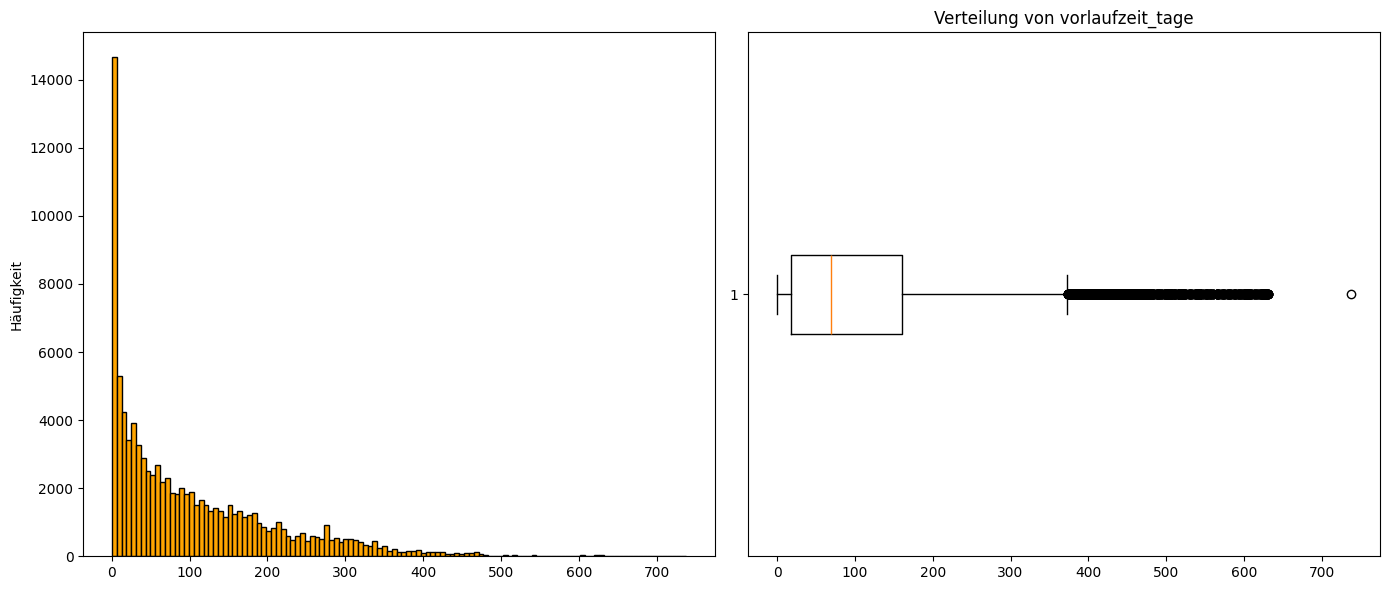

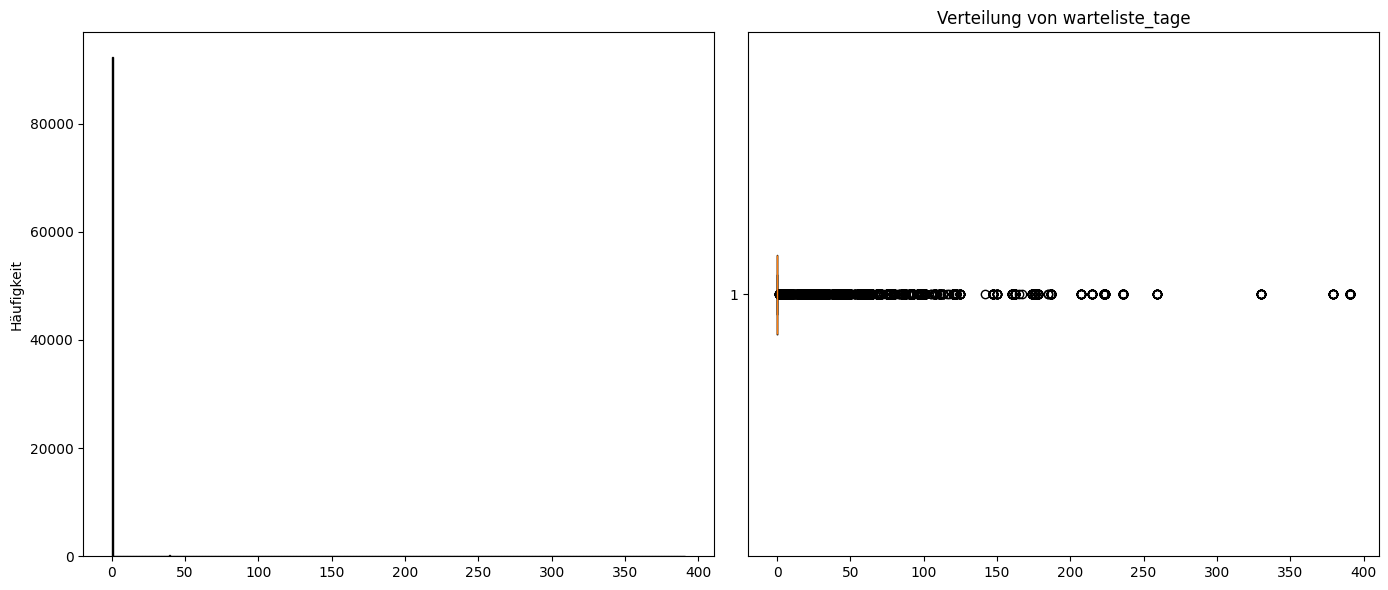

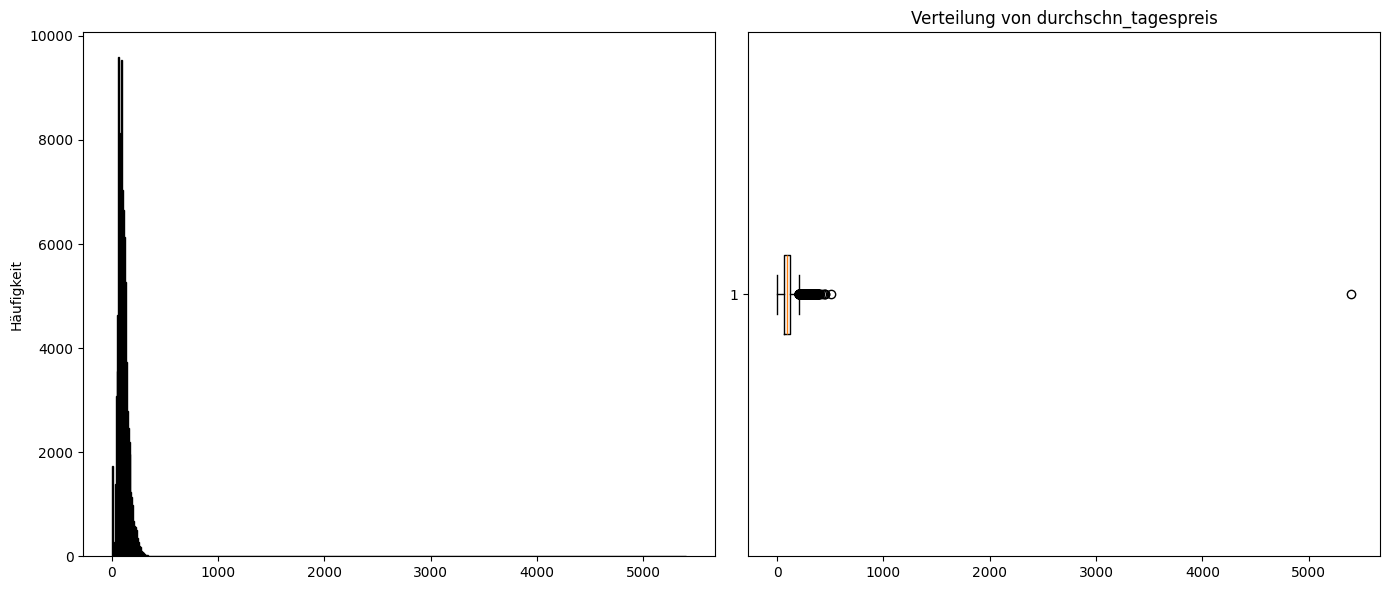

In [ ]:
df = df_train.copy()

cancel_rate = float(df.loc[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Ferienhotel"]
cancel_rate_holiday = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Stadthotel"]
cancel_rate_city = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] == 0]
cancel_rate_vorlaufzeit = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

print(f"Stornierungsraten:\nGesamt:       {cancel_rate:.2f} %\nFerienhotel:  {cancel_rate_holiday:.2f} %\nStadthotel:   {cancel_rate_city:.2f} %\n")

# TODO: Auswahl von Spalten zum plotten
# for column in df.select_dtypes(include=np.number).columns.drop(["storniert", "stammgast", "agentur_id"]):
for column in ["vorlaufzeit_tage", "warteliste_tage", "durchschn_tagespreis"]:
    _, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].hist(df[column].dropna(), bins="auto", color="orange", edgecolor="black")
    axes[0].set_ylabel("Häufigkeit")

    axes[1].boxplot(df[column].dropna(), vert=False)

    plt.title(f"Verteilung von {column}")
    plt.tight_layout()
    plt.show()

# (2 / 3) Vorverarbeitung und Feature Engineering

In [54]:
# Anzahl Feiertage im Buchungszeitraum
df_holidays = pd.read_csv("data/portugal_feiertage.csv")
df_holidays["datum"] = pd.to_datetime(df_holidays["datum"])
df_holidays = df_holidays.set_index("datum")


def map_holidays(df: pd.DataFrame) -> pd.DataFrame:
    """Berechnet die Anzahl an Feiertage innerhalb eines Buchungszeitraumes als neues Feature."""
    df = df.copy()
    df["abreisedatum"] = df["anreisedatum"] + pd.to_timedelta((df["naechte_wochenende"] + df["naechte_wochentag"]), unit="D")

    df["anzahl_feiertage"] = 0
    for d in df_holidays.index:
        df["anzahl_feiertage"] += ((df["anreisedatum"] <= d) & (df["abreisedatum"] >= d)).astype(int)

    return df.drop(columns=["abreisedatum"])

In [55]:
import country_converter as coco

# Manche Einträge kann country-converter nicht zuordnen
# Die Tabelle: https://de.wikipedia.org/wiki/ISO-3166-1-Kodierliste
# hat eine vollständige Liste und führt auch veraltete Codes auf
MANUAL_CONTINENT_MAPPING = {
    "TMP": "Asia",  # Osttimor (veraltet), aktueller Code: TLS
}


# TODO: Features Mapping für Test-Set
def add_country_features(df: pd.DataFrame) -> pd.DataFrame:
    """Ersetzt "herkunftsland" durch zwei neue Features.

    "herkunftskontinent": Kontinent des Herkunftslandes.
    "aus_portugal":       1 wenn Herkunftsland Portugal (PRT), sonst 0.
    """
    cc = coco.CountryConverter()
    df = df.copy()

    # Binäres Feature: Gast kommt aus Portugal
    # TODO: Auswahl weiterer Länder
    df["aus_portugal"] = (df["herkunftsland"] == "PRT").astype(bool)

    def map_continent(code):
        if pd.isna(code):
            return "Unbekannt"
        if code in MANUAL_CONTINENT_MAPPING:
            return MANUAL_CONTINENT_MAPPING[code]
        return cc.convert(code, to="continent")

    df["herkunftskontinent"] = df["herkunftsland"].apply(map_continent)
    return df.drop(columns=["herkunftsland"])

In [56]:
def features(df: pd.DataFrame, drop: list | None = None) -> pd.DataFrame:
    """Generiert oder transformiert neue Features."""
    drop = [] if drop is None else drop
    df = df.copy()

    df["anreisedatum"] = pd.to_datetime(df["anreisedatum"])
    df["stammgast"] = df["stammgast"].astype(str)  # Stammgast ist kategorisch
    df["agentur_id"] = df["agentur_id"].astype(str)  # Agenturen sind kategorisch

    df = map_holidays(df)
    # df = add_country_features(df)  # TODO: Ersetzen durch Stonierungsrate nach Land, Einteilung nach Prozenten Verteilung ausgeben lassen

    return df.drop(columns=[*drop, "anreisedatum", "agentur_id"])

In [57]:
from sklearn.model_selection import train_test_split

# Duplizierte Datenpunkte entfernen (hier vor dem Split)
print(f"Anzahl Duplikate: {df_train.duplicated().sum()}")
df_train = df_train.drop_duplicates()

# Entfernen von nicht relevanten Spalten
df_train = features(df_train, ["reservierungsstatus", "reservierungsstatus_datum"])

# Im Folgendem wird nur noch der Trainingsdatensatz betrachtet um Data Leakage zu vermeiden
X_train, X_valid, y_train, y_valid = train_test_split(
    df_train.drop(columns=["storniert"]),
    df_train["storniert"],
    test_size=0.2,
    random_state=42,
)

categorical = X_train.select_dtypes(exclude=np.number).columns
numerical = X_train.select_dtypes(include=np.number).columns

Anzahl Duplikate: 286


In [58]:
# Ergebnis von Transformation der Länder prüfen
print(
    "Verteilung Kontinente (Trainingsdaten):\n"
    # f"{X_train['herkunftskontinent'].value_counts()}\n\n"
    f"Anteil Gäste aus Portugal: "
    # f"{X_train['aus_portugal'].astype(int).mean():.1%}\n"
)

# Ausgabe kategorischer Features
print(f"Kategorische Features ({len(categorical)}):\n")
for col in categorical:
    n_unique = X_train[col].nunique()
    print(f"{col:25} {n_unique:5} eindeutige Werte")

display("Trainingsdatensatz (kategorische Features):", X_train[categorical])

# Spalten die fehlende Werte enthalten ausgeben
missing = X_train.isna().sum()
display("Spalten mit fehlenden Werten:", missing[missing > 0])

# Ausreißern veranschaulichen
display(
    "Verteilung numerischer Features:",
    X_train.select_dtypes(include=np.number).describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]),
)

Verteilung Kontinente (Trainingsdaten):
Anteil Gäste aus Portugal: 
Kategorische Features (10):

hotel_typ                     2 eindeutige Werte
verpflegung                   5 eindeutige Werte
herkunftsland               168 eindeutige Werte
marktsegment                  8 eindeutige Werte
buchungskanal                 5 eindeutige Werte
stammgast                     2 eindeutige Werte
gebuchter_zimmertyp          10 eindeutige Werte
zugewiesener_zimmertyp       12 eindeutige Werte
anzahlungsart                 3 eindeutige Werte
kundentyp                     4 eindeutige Werte


'Trainingsdatensatz (kategorische Features):'

,hotel_typ,verpflegung,herkunftsland,marktsegment,buchungskanal,stammgast,gebuchter_zimmertyp,zugewiesener_zimmertyp,anzahlungsart,kundentyp
76374,Stadthotel,Frühstück,PRT,Online Reisebüro,Reisebüro,0,D,K,Ohne Anzahlung,Einzelbucher
66460,Stadthotel,Frühstück,PRT,Direktbuchung,Direkt,0,D,D,Ohne Anzahlung,Einzelbucher
82131,Stadthotel,Frühstück,FRA,Offline Reisebüro,Reisebüro,0,A,A,Ohne Anzahlung,Einzelbucher
44586,Stadthotel,Frühstück,GBR,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
49014,Stadthotel,Frühstück,PRT,Direktbuchung,Direkt,0,A,A,Ohne Anzahlung,Einzelbucher
...,...,...,...,...,...,...,...,...,...,...
6277,Ferienhotel,Frühstück,MAR,Online Reisebüro,Reisebüro,0,G,G,Ohne Anzahlung,Einzelbucher
55072,Stadthotel,Frühstück,ESP,Online Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
77084,Stadthotel,Frühstück,PRT,Offline Reisebüro,Reisebüro,0,D,D,Ohne Anzahlung,Einzelbucher
860,Ferienhotel,Frühstück,ESP,Online Reisebüro,Reisebüro,0,D,E,Ohne Anzahlung,Einzelbucher


'Spalten mit fehlenden Werten:'

kinder             3
herkunftsland    300
dtype: int64

'Verteilung numerischer Features:'

,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,frueh_stornierungen,frueh_buchungen_eingehalten,buchungsaenderungen,warteliste_tage,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,anzahl_feiertage
count,76180.000000,76180.000000,76180.000000,76180.000000,76177.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000
mean,103.834602,0.929942,2.498307,1.858112,0.103260,0.007981,0.085757,0.136519,0.220924,2.293712,101.953647,0.062930,0.574587,0.176424
std,106.767568,0.998556,1.911787,0.584068,0.397326,0.101392,0.841162,1.488057,0.655072,17.337603,51.788280,0.247444,0.794688,0.411521
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5%,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,38.500000,0.000000,0.000000,0.000000
10%,3.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.609000,0.000000,0.000000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,69.310000,0.000000,0.000000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,94.470000,0.000000,0.000000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,125.900000,0.000000,1.000000,0.000000
90%,264.100000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,164.211000,0.000000,2.000000,1.000000


'Korrelation der numerischen Features mit storniert:'

storniert                      1.000000
vorlaufzeit_tage               0.291703
frueh_stornierungen            0.111456
erwachsene                     0.059906
warteliste_tage                0.051933
durchschn_tagespreis           0.044816
anzahl_feiertage               0.035741
naechte_wochentag              0.024607
kinder                         0.008338
naechte_wochenende             0.001288
babys                         -0.031539
frueh_buchungen_eingehalten   -0.057070
buchungsaenderungen           -0.141515
parkplaetze_benoetigt         -0.194634
anzahl_sonderwuensche         -0.235324
Name: storniert, dtype: float64

'Korrelation der kategorischen Features mit storniert:'

storniert                         1.000000
anzahlungsart_Nicht erstattbar    0.478201
herkunftsland_PRT                 0.333968
marktsegment_Gruppen              0.219147
zugewiesener_zimmertyp_A          0.196030
                                    ...   
zugewiesener_zimmertyp_D         -0.129579
hotel_typ_Ferienhotel            -0.132513
buchungskanal_Direkt             -0.151186
marktsegment_Direktbuchung       -0.152973
anzahlungsart_Ohne Anzahlung     -0.474224
Name: storniert, Length: 221, dtype: float64

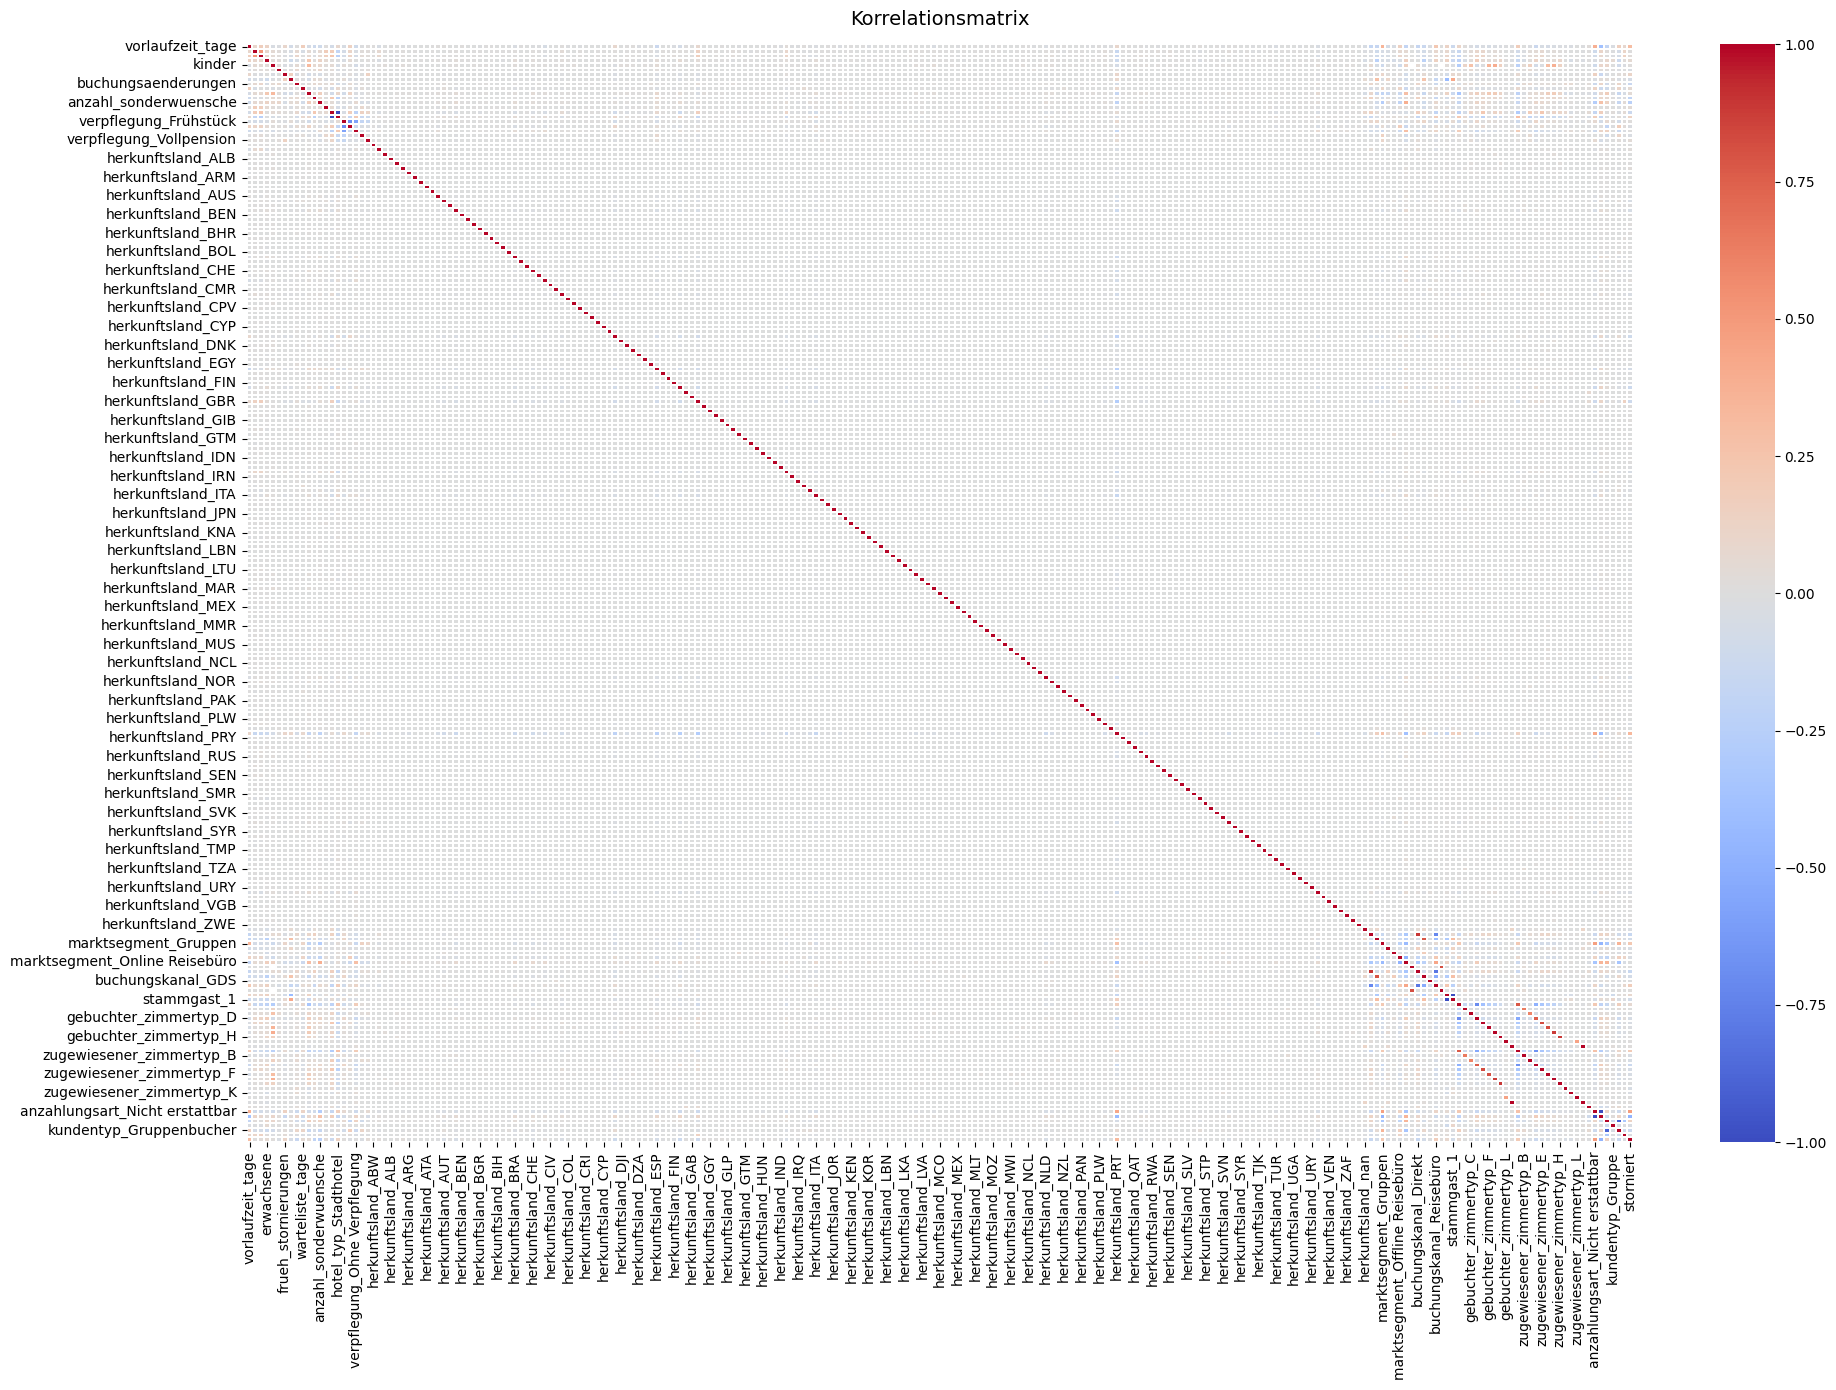

In [59]:
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder


def show_correlations(df: pd.DataFrame, target: pd.DataFrame, text: str) -> None:
    """Ausgabe der Korrelationen."""
    df_corr = df.copy()
    df_corr["storniert"] = target.copy()

    correlations = df_corr.corr()
    display(text, correlations["storniert"].sort_values(ascending=False))


show_correlations(X_train[numerical], y_train, "Korrelation der numerischen Features mit storniert:")

encoding = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# TODO: Entfernen nach Behandlung
# categorical = categorical.drop("agentur_id")  # TODO: Agentur in Risikogruppen unterteilen
df_encoded = encoding.fit_transform(X=X_train[categorical])
df_encoded = pd.DataFrame(df_encoded, columns=encoding.get_feature_names_out(), index=X_train.index)

show_correlations(df_encoded, y_train, "Korrelation der kategorischen Features mit storniert:")

# Korrelationsmatrix der Features
df_heatmap = pd.concat([X_train[numerical], df_encoded], axis=1)
df_heatmap["storniert"] = y_train

_, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    df_heatmap.corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot=False,
    ax=ax,
)
plt.title("Korrelationsmatrix", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def clip_numericals(X: np.ndarray) -> np.ndarray:
    """Behandlung von Ausreißern."""
    # lower = np.percentile(X, 1, axis=0)  # TODO: Lower entfernen
    upper = np.percentile(X, 99, axis=0)

    return np.clip(X, 0, upper)


numerical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),  # Kinder (keine Angabe = keine Kinder)
        ("clip", FunctionTransformer(clip_numericals, validate=False)),
        ("scaler", StandardScaler()),  # Für logistische Regression
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Keine Angabe")),  # Herkunftsland und Agenturen
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical), ("cat", categorical_pipeline, categorical)])

# (4) Training der Modelle

In [61]:
def optimize_threshold_kosten(
    y_true: pd.Series,
    y_prob: np.ndarray,
    df_features: pd.DataFrame,
    cost_fp: float = 250.0,
    cost_fn_faktor: float = 0.9,
) -> tuple[float, float]:
    """
    Berechnet den optimalen Schwellwert durch Minimierung der Gesamtkosten
    über alle möglichen Schwellwert-Kandidaten.

    Parameter:
    - y_true:         Wahre Labels (0 oder 1)
    - y_prob:         Vorhergesagte Wahrscheinlichkeiten für Klasse 1 (Stornierung)
    - df_features:    DataFrame mit 'durchschn_tagespreis', 'naechte_wochenende', 'naechte_wochentag'
    - cost_fp:        Fixkosten pro False Positive (Standard: 250 €)
    - cost_fn_faktor: Multiplikator auf Umsatz pro False Negative (Standard: 0.9)

    Rückgabe:
    - best_threshold (float), min_kosten (float)
    """
    # Aufenthaltsdauer = Wochennächte + Wochendendnächte
    aufenthaltsdauer = df_features["naechte_wochenende"] + df_features["naechte_wochentag"]

    # FN-Kosten pro Buchung: entgangener Umsatz = 90% des Tagespreises * Nächte
    fn_kosten = (df_features["durchschn_tagespreis"] * aufenthaltsdauer * cost_fn_faktor).values

    y = y_true.values

    # Alle einzigartigen Wahrscheinlichkeiten als Schwellwert-Kandidaten
    kandidaten = np.unique(y_prob)

    # Startwerte: neutraler Schwellwert und unendlich hohe Kosten
    best_t, min_kosten = 0.5, np.inf

    # Jeden möglichen Schwellwert ausprobieren
    for t in kandidaten:
        # Vorhersage: 1 (Storno) wenn Wahrscheinlichkeit >= Schwellwert, sonst 0
        z = (y_prob >= t).astype(int)

        # FP-Kosten: Modell sagt Storno, Gast kommt dennoch → 250€ pro Fall
        fp_gesamt = cost_fp * np.sum((z == 1) & (y == 0))

        # FN-Kosten: Modell sagt kein Storno, Gast storniert dennoch → entgangener Umsatz
        fn_gesamt = np.sum(fn_kosten[(z == 0) & (y == 1)])

        gesamtkosten = fp_gesamt + fn_gesamt

        # Wenn dieser Schwellwert günstiger ist, als bisher besten merken
        if gesamtkosten < min_kosten:
            min_kosten = gesamtkosten
            best_t = t

    # Besten Schwellwert und zugehörige Mindestkosten zurückgeben
    return best_t, min_kosten


In [62]:
import gurobipy as gp
from gurobipy import GRB


def optimize_threshold_gurobi(y_true: pd.Series, y_prob: pd.Series, df_features: pd.DataFrame) -> tuple[float, float]:
    """Minimiert Gesamtkosten und berechnet Schwellwert."""
    aufenthaltsdauer = df_features["naechte_wochenende"] + df_features["naechte_wochentag"]
    fn_kosten = (df_features["durchschn_tagespreis"] * aufenthaltsdauer * 0.9).values

    y = y_true.values
    p = y_prob
    N = len(y)

    env = gp.Env(empty=True)
    env.setParam("OutputFlag", 0)
    env.start()
    m = gp.Model("Threshold_Optimierung", env=env)

    t = m.addVar(vtype=GRB.CONTINUOUS, lb=0.0, ub=1.0, name="threshold")
    z = m.addVars(N, vtype=GRB.BINARY, name="z")

    M = 1.01
    eps = 1e-5

    for i in range(N):
        m.addConstr(p[i] - t >= -M * (1 - z[i]), name=f"lower_{i}")
        m.addConstr(p[i] - t <= M * z[i] - eps, name=f"upper_{i}")

    kosten = gp.LinExpr()
    for i in range(N):
        if y[i] == 0:
            kosten += 250.0 * z[i]
        else:
            kosten += fn_kosten[i] * (1 - z[i])

    m.setObjective(kosten, GRB.MINIMIZE)
    m.optimize()

    if m.status == GRB.OPTIMAL:
        return m.ObjVal, t.X
    raise ValueError("Gurobi konnte keine optimale Lösung finden.")

In [63]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV


def show_metrics(data: pd.DataFrame, pred: pd.DataFrame, title: str = "") -> None:
    """Ausgabe der relevanten Metriken."""
    tn, fp, fn, tp = confusion_matrix(data, pred).ravel()

    print(
        f"{title}\n"
        f"Accuracy:             {accuracy_score(data, pred) * 100:.7f}\n"
        f"Precision:            {precision_score(data, pred) * 100:.7f}\n"
        f"Recall:               {recall_score(data, pred) * 100:.7f}\n"
        f"False positive rate:  {fp / (fp + tn) * 100:.7f}\n"
    )


def show_feature_importances(model, name: str) -> None:
    """Ausgabe der Feature Importances."""
    onehot = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    feature_names_cat = onehot.get_feature_names_out(categorical)

    feature_names = numerical.tolist() + feature_names_cat.tolist()

    # Wichtigkeit der Features beim splitten
    importances = model.named_steps[name].feature_importances_

    df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

    display("Feature Importances:", df_importances)


def show_permutation_importances(model) -> None:
    """Ausgabe der Permutation Importances."""
    result = permutation_importance(model, X_train, y_train, n_repeats=10, random_state=42, scoring="accuracy")

    df_importances = pd.DataFrame({"feature": X_train.columns, "importance": result.importances_mean}).sort_values("importance", ascending=False)

    display("Permutation Importances:", df_importances)


def give_best_models(name: str, ident: str, search: GridSearchCV, output_importances: bool = True) -> dict:
    """Ausgabe Modellergebnisse und Rückgabe Dictionary mit wichtigsten Parametern."""
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_train)
    show_metrics(y_train, y_pred, title=f"{name} (Trainingsdaten)")

    y_pred = best_model.predict(X_valid)
    show_metrics(y_valid, y_pred, title=f"{name} (Validationsdaten)")

    display("Beste Parameter:", search.best_params_)

    if output_importances:
        show_feature_importances(best_model, ident)
    # show_permutation_importances(best_model)

    # costs, threshold = optimize_threshold_gurobi(y_valid, y_pred, X_valid)
    threshold, costs = optimize_threshold_kosten(y_valid, y_pred, X_valid)
    # costs, threshold = 0, 0

    return {
        name: {
            "Model": best_model,
            "Accuracy": round(accuracy_score(y_valid, y_pred), 5),
            "Parameter": search.best_params_,
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }


models = []
CV = 2
VERBOSE = 1

In [64]:
from sklearn.tree import DecisionTreeClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("tree", DecisionTreeClassifier(random_state=42))]),
    param_grid={
        "tree__max_depth": [15, 30],
        "tree__min_samples_split": [25, 100],
        "tree__min_samples_leaf": [20, 50],
        "tree__criterion": ["entropy"],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(give_best_models("Entscheidungsbaum", "tree", search))

Fitting 2 folds for each of 8 candidates, totalling 16 fits


Entscheidungsbaum (Trainingsdaten)
Accuracy:             84.9645576
Precision:            81.7984295
Recall:               76.2634160
False positive rate:  9.9392198

Entscheidungsbaum (Validationsdaten)
Accuracy:             83.9808884
Precision:            79.6476034
Recall:               75.9612646
False positive rate:  11.3356620



'Beste Parameter:'

{'tree__criterion': 'entropy',
 'tree__max_depth': 15,
 'tree__min_samples_leaf': 20,
 'tree__min_samples_split': 100}

'Feature Importances:'

,feature,importance
228,anzahlungsart_Nicht erstattbar,0.368123
196,marktsegment_Online Reisebüro,0.134003
0,vorlaufzeit_tage,0.088632
12,anzahl_sonderwuensche,0.066368
11,parkplaetze_benoetigt,0.062195
...,...,...
226,zugewiesener_zimmertyp_P,0.000000
229,anzahlungsart_Ohne Anzahlung,0.000000
227,anzahlungsart_Erstattbar,0.000000
231,kundentyp_Gruppe,0.000000


In [65]:
X_train

,hotel_typ,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,herkunftsland,marktsegment,...,gebuchter_zimmertyp,zugewiesener_zimmertyp,buchungsaenderungen,anzahlungsart,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,anzahl_feiertage
76374,Stadthotel,90,0,4,0,0.0,0,Frühstück,PRT,Online Reisebüro,...,D,K,5,Ohne Anzahlung,0,Einzelbucher,33.51,0,2,0
66460,Stadthotel,1,1,0,1,0.0,0,Frühstück,PRT,Direktbuchung,...,D,D,0,Ohne Anzahlung,0,Einzelbucher,100.59,0,0,0
82131,Stadthotel,26,1,2,2,0.0,0,Frühstück,FRA,Offline Reisebüro,...,A,A,0,Ohne Anzahlung,0,Einzelbucher,79.15,0,0,0
44586,Stadthotel,148,1,2,2,0.0,0,Frühstück,GBR,Online Reisebüro,...,D,D,0,Ohne Anzahlung,0,Einzelbucher,117.99,0,0,0
49014,Stadthotel,0,1,0,1,0.0,0,Frühstück,PRT,Direktbuchung,...,A,A,0,Ohne Anzahlung,0,Einzelbucher,88.19,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6277,Ferienhotel,43,2,2,2,2.0,0,Frühstück,MAR,Online Reisebüro,...,G,G,0,Ohne Anzahlung,0,Einzelbucher,268.86,0,0,0
55072,Stadthotel,192,0,4,2,0.0,0,Frühstück,ESP,Online Reisebüro,...,D,D,0,Ohne Anzahlung,0,Einzelbucher,157.02,0,0,0
77084,Stadthotel,182,2,5,2,0.0,0,Frühstück,PRT,Offline Reisebüro,...,D,D,0,Ohne Anzahlung,0,Einzelbucher,91.37,0,0,0
860,Ferienhotel,89,2,3,2,0.0,0,Frühstück,ESP,Online Reisebüro,...,D,E,1,Ohne Anzahlung,0,Einzelbucher,154.49,0,2,1


In [66]:
from sklearn.linear_model import LogisticRegression

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("logistic", LogisticRegression(random_state=42))]),
    param_grid={
        "logistic__C": [0.01, 0.1, 1, 10],
        "logistic__penalty": ["l2"],
        "logistic__solver": ["lbfgs"],
        "logistic__max_iter": [500],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(give_best_models("Logistische Regression", "logistic", search, False))

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Logistische Regression (Trainingsdaten)
Accuracy:             81.6854818
Precision:            80.9927467
Recall:               65.8753287
False positive rate:  9.0545772

Logistische Regression (Validationsdaten)
Accuracy:             81.7967027
Precision:            80.5150215
Recall:               66.7900883
False positive rate:  9.4394544



'Beste Parameter:'

{'logistic__C': 1,
 'logistic__max_iter': 500,
 'logistic__penalty': 'l2',
 'logistic__solver': 'lbfgs'}

In [67]:
from sklearn.ensemble import RandomForestClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("rf", RandomForestClassifier(random_state=42))]),
    param_grid={
        "rf__n_estimators": [100, 200],
        "rf__max_depth": [10, 20],
        "rf__min_samples_split": [2, 10],
        "rf__max_features": ["sqrt", "log2"],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(give_best_models("Random Forest", "rf", search))

Fitting 2 folds for each of 16 candidates, totalling 32 fits
Random Forest (Trainingsdaten)
Accuracy:             88.9065371
Precision:            91.1948106
Recall:               77.4433151
False positive rate:  4.3795013

Random Forest (Validationsdaten)
Accuracy:             86.1650740
Precision:            87.6437275
Recall:               72.7285674
False positive rate:  5.9880240



'Beste Parameter:'

{'rf__max_depth': 20,
 'rf__max_features': 'sqrt',
 'rf__min_samples_split': 2,
 'rf__n_estimators': 200}

'Feature Importances:'

,feature,importance
228,anzahlungsart_Nicht erstattbar,0.105037
229,anzahlungsart_Ohne Anzahlung,0.103640
0,vorlaufzeit_tage,0.097738
148,herkunftsland_PRT,0.093717
12,anzahl_sonderwuensche,0.066123
...,...,...
5,babys,0.000000
156,herkunftsland_SDN,0.000000
108,herkunftsland_LAO,0.000000
123,herkunftsland_MLI,0.000000


In [68]:
from sklearn.ensemble import GradientBoostingClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("gb", GradientBoostingClassifier(random_state=42))]),
    param_grid={
        "gb__n_estimators": [100],
        "gb__learning_rate": [0.05],
        "gb__max_depth": [3],
        "gb__min_samples_split": [2],
        "gb__min_samples_leaf": [1],
        "gb__subsample": [0.8, 1.0],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(give_best_models("Gradient Boosting", "gb", search))

Fitting 2 folds for each of 2 candidates, totalling 4 fits
Gradient Boosting (Trainingsdaten)
Accuracy:             83.2777632
Precision:            81.8411149
Recall:               70.3319355
False positive rate:  9.1399192

Gradient Boosting (Validationsdaten)
Accuracy:             83.0883125
Precision:            81.0387065
Recall:               70.6636286
False positive rate:  9.6556886



'Beste Parameter:'

{'gb__learning_rate': 0.05,
 'gb__max_depth': 3,
 'gb__min_samples_leaf': 1,
 'gb__min_samples_split': 2,
 'gb__n_estimators': 100,
 'gb__subsample': 0.8}

'Feature Importances:'

,feature,importance
228,anzahlungsart_Nicht erstattbar,0.430956
148,herkunftsland_PRT,0.111946
0,vorlaufzeit_tage,0.108341
196,marktsegment_Online Reisebüro,0.100533
12,anzahl_sonderwuensche,0.078810
...,...,...
222,zugewiesener_zimmertyp_H,0.000000
226,zugewiesener_zimmertyp_P,0.000000
227,anzahlungsart_Erstattbar,0.000000
231,kundentyp_Gruppe,0.000000


In [69]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

search = GridSearchCV(
    estimator=Pipeline(
        [
            ("preprocessor", preprocessor),
            (
                "stack",
                StackingClassifier(
                    estimators=[
                        ("tree", DecisionTreeClassifier(max_depth=10, min_samples_split=10, random_state=42)),
                        ("gb", GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=42)),
                        ("rf", RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)),
                    ],
                    final_estimator=LogisticRegression(max_iter=500, random_state=42),
                    cv=CV,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    param_grid={"stack__final_estimator__C": [0.1, 1, 10], "stack__final_estimator__penalty": ["l2"]},
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(give_best_models("Stacking", "stack", search, False))

Fitting 2 folds for each of 3 candidates, totalling 6 fits
Stacking (Trainingsdaten)
Accuracy:             86.4334471
Precision:            85.0163251
Recall:               76.8071647
False positive rate:  7.9284792

Stacking (Validationsdaten)
Accuracy:             85.3407540
Precision:            83.3070866
Recall:               75.3346625
False positive rate:  8.8157019



'Beste Parameter:'

{'stack__final_estimator__C': 1, 'stack__final_estimator__penalty': 'l2'}

In [70]:
best_entry = max(models, key=lambda x: next(iter(x.values()))["Accuracy"])

best_model = next(iter(best_entry.values()))["Model"]

X_train["storniert"] = y_train
X_valid["storniert"] = y_valid

X_train["pred"] = None
X_valid["pred"] = None

# TODO: In Feature Pipeline aufnehmen
for hotel in ["Stadthotel", "Ferienhotel"]:
    X_train_h = X_train[X_train["hotel_typ"] == hotel].copy()
    y_train_h = X_train_h["storniert"]
    X_train_feat = X_train_h.drop(columns=["storniert", "pred"])

    X_valid_h = X_valid[X_valid["hotel_typ"] == hotel].copy()
    y_valid_h = X_valid_h["storniert"]
    X_valid_feat = X_valid_h.drop(columns=["storniert", "pred"])

    best_model.fit(X_train_feat, y_train_h)

    y_pred = best_model.predict(X_train_feat)
    X_train.loc[X_train_h.index, "pred"] = y_pred

    y_pred = best_model.predict(X_valid_feat)
    X_valid.loc[X_valid_h.index, "pred"] = y_pred


show_metrics(y_train, X_train["pred"].astype(int), "Hotels getrennt (Trainingsdaten)")
show_metrics(y_valid, X_valid["pred"].astype(int), "Hotels getrennt (Validationsdaten)")

# costs, threshold = optimize_threshold_gurobi(y_valid, X_valid["pred"].astype(int), X_valid)
threshold, costs = optimize_threshold_kosten(y_valid, X_valid["pred"].astype(int), X_valid)
# costs, threshold = 0, 0

models.append(
    {
        "Hotels getrennt": {
            "Model": best_model,
            "Accuracy": round(accuracy_score(y_valid, X_valid["pred"].astype(int)), 5),
            "Parameter": None,
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }
)

Hotels getrennt (Trainingsdaten)
Accuracy:             90.2297191
Precision:            92.3020318
Recall:               80.2402445
False positive rate:  3.9194871

Hotels getrennt (Validationsdaten)
Accuracy:             86.5063530
Precision:            87.7160285
Recall:               73.7254343
False positive rate:  6.0296075



# (5) Evaluation

In [71]:
lowest_cost_model = min(models, key=lambda x: next(iter(x.values()))["Gesamtkosten"])

rows = []

for model in models:
    name, values = next(iter(model.items()))

    rows.append(
        {
            "name": name,
            "Accuracy": values["Accuracy"],
            "Gesamtkosten": values["Gesamtkosten"],
            "Schwellwert": values["Schwellwert"],
        }
    )

df_models = pd.DataFrame(rows)

display("Modelle geordnet nach Gesamtkosten:", df_models.sort_values(by="Gesamtkosten"))

'Modelle geordnet nach Gesamtkosten:'

,name,Accuracy,Gesamtkosten,Schwellwert
5,Hotels getrennt,0.86506,846443.222,1
2,Random Forest,0.86165,879798.285,1
4,Stacking,0.85341,887783.494,1
0,Entscheidungsbaum,0.83981,979385.995,1
1,Logistische Regression,0.81797,1036554.370,1
3,Gradient Boosting,0.83088,1093312.152,1


# (6) Vorhersage

In [72]:
# Bestes Modell auf kompletten Datensatz trainieren
X = df_train.drop(columns=["storniert"])
y = df_train["storniert"]

best_entry = max(models, key=lambda x: next(iter(x.values()))["Accuracy"])

best_model = next(iter(best_entry.values()))["Model"]
best_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [73]:
df_test

,buchungs_id,hotel_typ,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,gebuchter_zimmertyp,zugewiesener_zimmertyp,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche
0,1,Stadthotel,2017-05-14,33,2,3,1,0.0,0,Frühstück,...,A,A,0,Ohne Anzahlung,459.0,0,Gruppenbucher,129.67,0,0
1,2,Ferienhotel,2015-10-12,284,2,5,2,0.0,0,Frühstück,...,E,E,0,Ohne Anzahlung,273.0,0,Gruppenbucher,77.03,0,0
2,3,Stadthotel,2016-11-01,166,0,3,1,0.0,0,Frühstück,...,A,A,0,Nicht erstattbar,236.0,0,Einzelbucher,110.11,0,0
3,4,Ferienhotel,2017-06-06,328,2,10,2,0.0,0,Halbpension,...,E,E,0,Ohne Anzahlung,57.0,0,Einzelbucher,27.14,0,2
4,5,Stadthotel,2017-08-20,2,2,0,1,0.0,0,Frühstück,...,A,A,1,Ohne Anzahlung,98.0,0,Gruppenbucher,114.33,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23873,23874,Ferienhotel,2017-02-06,8,1,1,3,0.0,0,Unbekannt,...,A,C,1,Ohne Anzahlung,NaN,0,Gruppenbucher,120.32,0,0
23874,23875,Stadthotel,2016-01-15,10,8,22,2,0.0,0,Ohne Verpflegung,...,A,A,0,Ohne Anzahlung,9.0,0,Einzelbucher,73.50,0,1
23875,23876,Stadthotel,2015-12-05,69,2,1,2,0.0,0,Ohne Verpflegung,...,A,A,0,Ohne Anzahlung,8.0,0,Einzelbucher,96.28,0,2
23876,23877,Stadthotel,2016-09-26,249,1,3,2,0.0,0,Frühstück,...,A,A,0,Nicht erstattbar,3.0,0,Einzelbucher,94.50,0,0


In [74]:
df_test = features(df_test)

y_pred = best_model.predict(df_test)

df_test["storniert_pred"] = y_pred
df_test[["buchungs_id", "storniert_pred"]].to_csv("data/vorhersage.csv", index=False)